In [280]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics # 분류와 숫자 예측에 사용하는 모델 모음,모델의 예측 성능을 평가하는 도구 모음
from sklearn.neighbors import KNeighborsClassifier  #분류(가까운 이웃 데이터를 참고해 종류를 분류)
from sklearn.neighbors import KNeighborsRegressor   #예측(가까운 이웃데이터를 참고해 숫자를 예측)

from sklearn.preprocessing import PolynomialFeatures # 다항특성 (x², x₁ × x₂ 같은 특성을 추가)
from sklearn.preprocessing import OneHotEncoder      # 원핫인코딩(문자형 번주를 0과1로 변환)

from sklearn.linear_model import LinearRegression   #예측 (입력과 결과의 선형관례를 학습해 숫자를 예측)
from sklearn.linear_model import Ridge              #릿지 (계수가 지나치게 커지는 것을 억제하는 선형 회귀)
from sklearn.linear_model import Lasso              #라쏘 (일부 계수를 0으로 만들어 특성 선택에도 활용하는 선형 회귀)
from sklearn.linear_model import LogisticRegression #분류
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위 (실제값과 예측값의 차이를 절댓값으로 구한 뒤 평균 계산)
from sklearn.preprocessing import StandardScaler # 표준화 (각 특성을 평균 0, 표준편차 1 기준으로 표준화)
from sklearn.model_selection import train_test_split #(데이터를 학습용과 평가용으로 분리)
from scipy.special import expit                     #exip:이진분류함수
from scipy.special import softmax                   #softmax: 다중분류함수

# 결정트리
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree                  #그래프지원

# 교차검증
from sklearn.model_selection import cross_validate      # 자동 반복

# 분할기
from sklearn.model_selection import StratifiedKFold

from sklearn.model_selection import GridSearchCV

# 모델저장 - 실행파일
from sklearn.pipeline import make_pipeline
import joblib

# 학습한 모델 불러오기
import joblib

In [281]:
#1. 데이터 불러오기
wine = pd. read_csv('data/wine.csv')
wine.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [282]:
wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


In [283]:
wine.describe()

,alcohol,sugar,pH,class
count,6497.000000,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501,0.753886
std,1.192712,4.757804,0.160787,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,14.900000,65.800000,4.010000,1.000000


In [284]:
# 2. data, label 분리
data= wine[wine.columns[:-1]].values # 2차배열
label = wine['class'].values

In [285]:
data[:2]

array([[9.4 , 1.9 , 3.51],
       [9.8 , 2.6 , 3.2 ]])

In [286]:
np.unique(label)  # label은 현재 numpy 배열, 2종류 / # 0-red wine, 1-white wine

array([0., 1.])

In [287]:
label = wine['class'].map({0: 'red wine', 1: 'white wine'}).values

In [288]:
label[:2] #1차원 배열 ['red wine', 'red wine']
label.unique()

<StringArray>
['red wine', 'white wine']
Length: 2, dtype: str

In [289]:
# 3. 학습, 테스트 데이터 분리
train_data, test_data, train_label, test_label = train_test_split(data, label, stratify=label)

In [290]:
# 4. logisticRegression전 정규화 작업 필수

ss=StandardScaler()
ss.fit(train_data)

train_scaled= ss.transform(train_data)
test_scaled= ss.transform(test_data)

In [291]:
# 5. logisticRegression

lr = LogisticRegression(C=20, max_iter=1000)
lr.fit(train_scaled, train_label)

print("train정확도:", lr.score(train_scaled, train_label))
print("test정확도:", lr.score(test_scaled, test_label))

train정확도: 0.7807881773399015
test정확도: 0.7784615384615384


In [292]:
# 5-1. 규제 C값 찾기
train_score =[]
test_score= []
cc=[0.001,0.01,0.1,1,10,20,50,100]
for c in cc:
    lr=LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled, train_label)

    train_score.append(lr.score(train_scaled, train_label))
    test_score.append(lr.score(test_scaled, test_label))

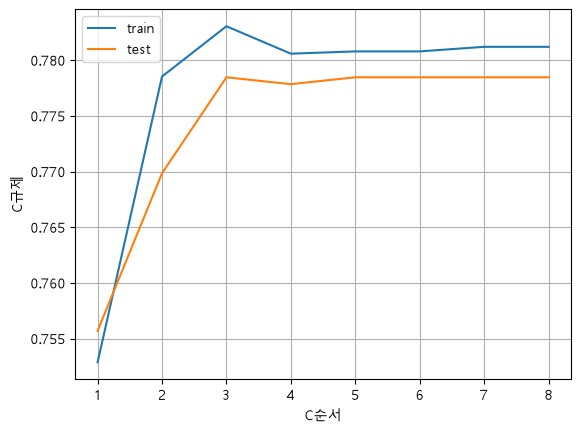

In [293]:
# 5-2 그래프

list1=[1,2,3,4,5,6,7,8]

plt.plot(list1,train_score)
plt.plot(list1,test_score)

plt.xlabel('C순서')
plt.ylabel('C규제')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [294]:
# 규제 20일때가 좋음

# 모델 저장하기
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=20,max_iter=1000)
)

# 원본 데이터로 학습 → 표준화는 파이프라인이 처리
model.fit(train_data, train_label)

joblib.dump(model, 'wine.joblib')
print('모델저장')


모델저장


In [310]:
# # 학습한 모델 불러오기
# import joblib
# ['red wine', 'white wine']

model_wine = joblib.load('wine.joblib')

In [311]:
model_wine.classes_

array(['red wine', 'white wine'], dtype=object)

In [313]:
in_data = input('alcohol,sugar,pH를 입력받아, 어떤 와인인지 분류확률을 출력하시오 (9.4,1.9,3.51)')
in_data=list(map(float,in_data.split(',')))

predict= model_wine.predict([in_data])
print(predict) # 1차배열

decisions= model_wine.decision_function([in_data])
decisions = expit(decisions) # 이진분류라 값이 1개 나옴.
print(decisions)

proba = model_wine.predict_proba([in_data])
print(proba)


if predict[0]=='red wine':
    proba=proba[0][0]
else:
    proba=proba[0][1]

print(f'분류와인 : {proba*100:.2f}% 의 확률로 {predict[0]} 판별됩니다.')

['red wine']
[0.22852441]
[[0.77147559 0.22852441]]
분류와인 : 77.15% 의 확률로 red wine 판별됩니다.
